In [2]:
# Business scaniro
# Imagie we work in It service company
# The company Receives tickets from employees and customers
# The ticket volume
# Open and resolved Tickets

# The support team needs  to monitor
# Total ticket valoume
#Open and resolved tickets
# SLA compliance
# Average resolution performancs
# Priority_wise performance
# Team qorkload
# Reopened tickets

# The operations team currently download ticets data and prepares manually
# We will automate this reporting process using python



In [4]:
# Tools and technologies
# 1.Python
# 2.pandas
# 3.Numpy
# 4.Matplotlib
# 5.Seanorn
# 6.Datetime
# 7.google collab or jupiter


In [5]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

from pathlib import Path




In [185]:
# Load the datasets

import pandas as pd
data_path = Path("data")

tickets = pd.read_csv("/content/tickets.csv")
support_teams = pd.read_csv("/content/support_teams.csv")
sla_ruls = pd.read_csv("/content/sla_rules.csv")


In [124]:
# inspect the validation
print(tickets.head())
print(tickets.info())
print(tickets.isnull().sum())

   ticket_id  customer_id  team_id           created_at          resolved_at  \
0       1001           25        2  2026-05-13 00:00:00  2026-05-13 02:27:24   
1       1002           21        4  2026-03-27 02:09:00                  NaN   
2       1003           23        3  2026-03-01 13:17:00                  NaN   
3       1004            6        2  2026-01-27 07:55:00                  NaN   
4       1005            8        5  2026-06-18 15:17:00  2026-06-19 19:06:40   

  priority    status  
0   Medium  Resolved  
1      Low   Pending  
2   Medium      Open  
3   Medium      Open  
4   Medium    Closed  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ticket_id    100 non-null    int64 
 1   customer_id  100 non-null    int64 
 2   team_id      100 non-null    int64 
 3   created_at   100 non-null    object
 4   resolved_at  59 non-null   

In [125]:
# check the duplicate tickets
duplicates = tickets.duplicated(
    subset=["ticket_id"],
    keep=False
).sum()
print(duplicates)

0


In [126]:
# convert timestamps
tickets["created_at"] = pd.to_datetime(
    tickets["created_at"],
    errors="coerce"
    )

tickets["resolved_at"] = pd.to_datetime(
    tickets["resolved_at"],
    errors="coerce"
)


In [127]:
# validatte timestamps

invalid_tickets = tickets[
    (tickets["created_at"].isna())
    |(
        tickets["resolved_at"].notnull())
    & (
        tickets["resolved_at"]<tickets["created_at"]
    )
]
print(invalid_tickets)

Empty DataFrame
Columns: [ticket_id, customer_id, team_id, created_at, resolved_at, priority, status]
Index: []


In [128]:
# Calculate resolution time
tickets["resolution_hour"] = (
    tickets["resolved_at"]
    -tickets["created_at"]

).dt.total_seconds()/3600

# substracing two datime values produce a time deffrent
# total seconds converts the diffrent into seconds
# Deviding by 3600 convert second into hours



In [129]:
# rename sla target column
sla_ruls = sla_ruls.rename(
    columns ={"resolution_hours":
              "sla_hours"}
)

In [130]:
# ADD sla targets
tickets = tickets.merge(
    sla_ruls,
    on="priority",
    how="left"
)

In [131]:
print(sla_ruls.columns.tolist())

['priority', 'sla_hours']


In [132]:
# Clasiify sla performance
tickets["sla_status"] = np.select(
    [
        tickets["resolved_at"].isna(),
        tickets["resolution_hour"]
        <= tickets["sla_hours"]
    ],
    [
        "pending",
        "Within SLA"
    ],
    default="SLA Breached"
)
# Explian Unsolved tickets are classufies as pending.
# Resolved tickets within the target are within sla
# Resolved tickets exceeding the target are sla breached

In [133]:
# Analyse ticket performancs
# Total tickets
total_tickets=len(tickets)
print("Total Tickets:",total_tickets)

# tickets by stutus
status_summary = (
    tickets.groupby("status")
    .value_counts()
  )
print("Tickets By Status:\n",status_summary)


Total Tickets: 100
Tickets By Status:
 status    ticket_id  customer_id  team_id  created_at           resolved_at          priority  resolution_hour  sla_hours  sla_status  
Closed    1005       8            5        2026-06-18 15:17:00  2026-06-19 19:06:40  Medium    27.827778        24         SLA Breached    1
          1007       7            3        2026-04-08 19:33:00  2026-04-08 23:51:00  Critical  4.300000         4          SLA Breached    1
          1013       22           1        2026-04-02 20:53:00  2026-04-02 22:51:55  Low       1.981944         72         Within SLA      1
          1018       24           1        2026-03-29 12:21:00  2026-03-29 19:11:40  Critical  6.844444         4          SLA Breached    1
          1019       20           5        2026-02-17 01:54:00  2026-02-17 09:27:03  Medium    7.550833         24         Within SLA      1
          1024       8            4        2026-07-16 15:53:00  2026-07-17 00:19:14  High      8.437222         8       

In [134]:
# ticlkets by priority
priority_summary = (
    tickets.groupby("priority")
    .value_counts()
)
print("Tickets By Priority:\n",priority_summary)

Tickets By Priority:
 priority  ticket_id  customer_id  team_id  created_at           resolved_at          status    resolution_hour  sla_hours  sla_status  
Critical  1007       7            3        2026-04-08 19:33:00  2026-04-08 23:51:00  Closed    4.300000         4          SLA Breached    1
          1018       24           1        2026-03-29 12:21:00  2026-03-29 19:11:40  Closed    6.844444         4          SLA Breached    1
          1054       12           2        2026-06-09 02:19:00  2026-06-09 06:25:27  Closed    4.107500         4          SLA Breached    1
          1061       15           1        2026-01-10 05:25:00  2026-01-10 10:00:43  Closed    4.595278         4          SLA Breached    1
          1085       16           4        2026-05-16 06:05:00  2026-05-16 06:40:05  Resolved  0.584722         4          Within SLA      1
High      1024       8            4        2026-07-16 15:53:00  2026-07-17 00:19:14  Closed    8.437222         8          SLA Breached  

In [141]:
# Average Resolution time

average_resolution = (
    tickets["resolution_hour"].mean()
)
print("Average Resolution Time:\n",average_resolution)

Average Resolution Time:
 25.343507532956682


In [146]:
# Average resolution time by team
team_resolution = (
    tickets.groupby("team_id")
    ["resolution_hour"].mean().reset_index()
)
team_resolution = team_resolution.merge(
    support_teams,
    on="team_id",
    how="left"
)
print(team_resolution)

   team_id  resolution_hour               team_name
0        1        21.660299            Service Desk
1        2         9.684556         Network Support
2        3        24.672265     Application Support
3        4        40.168788  Infrastructure Support
4        5        29.520116       Access Management


In [152]:
# Calculate sla compliance
# Exclude un resolved tickets from the resolved ticket compliance calculation

resolved_tickets = tickets[
    tickets["sla_status"].isin(
        ["within SLA","SLA Breached"]
    )
]
within_sla_count = (
    resolved_tickets["sla_status"]
    == "within SLA"
).sum()
resolved_count = len("resolved_tickets")

sla_percentage = (
    within_sla_count/resolved_count * 100

)
print(
    "SLA Compliance:\n",
    round(sla_percentage,2),"%"
)





SLA Compliance:
 0.0 %


In [157]:
# Analyse work load by team
team_workload =(
    tickets.groupby("team_id")
    .agg(
        total_tickets=("ticket_id","nunique"),
        average_resolution_hours=(
            "resolution_hour","mean"
            )
    ).reset_index()
)
team_workload = team_workload.merge(
    support_teams,
    on="team_id",
    how="left"
)
print(team_workload)

# egg(): it allows us to mutiple metrics in one groupby operation

   team_id  total_tickets  average_resolution_hours               team_name
0        1             17                 21.660299            Service Desk
1        2             19                  9.684556         Network Support
2        3             21                 24.672265     Application Support
3        4             23                 40.168788  Infrastructure Support
4        5             20                 29.520116       Access Management


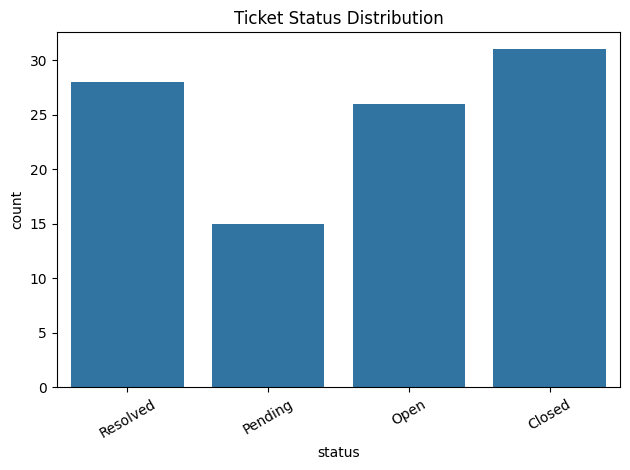

In [158]:
# Create visualisations
# Ticket status

sns.countplot(
    data=tickets,
    x="status"
)
plt.title("Ticket Status Distribution")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


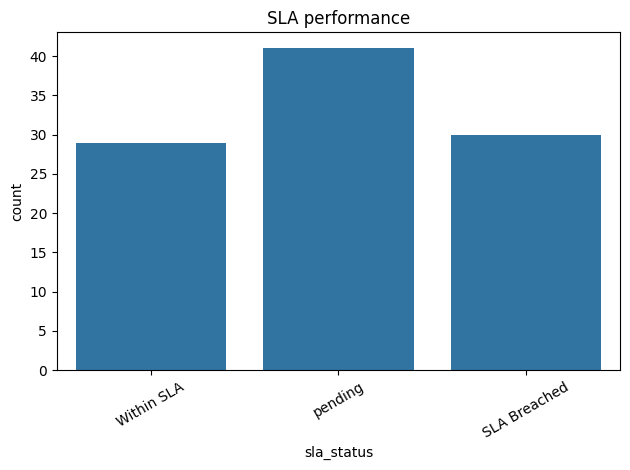

In [159]:
# sla status
sns.countplot(
    data=tickets,
    x="sla_status"
)
plt.title("SLA performance")
plt.xticks(rotation=30)
plt,plt.tight_layout()
plt.show()

<Axes: xlabel='priority', ylabel='resolution_hour'>

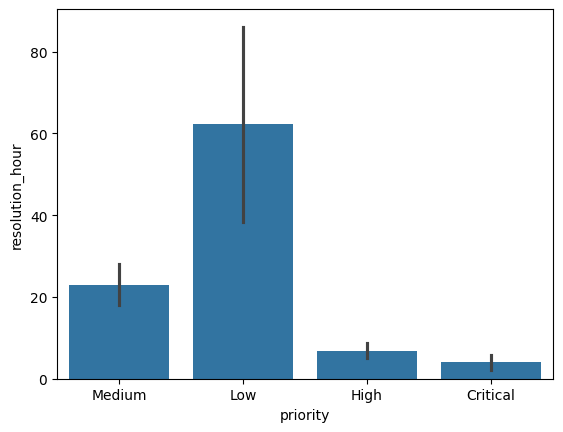

In [161]:
# Average resolution by priority

sns.barplot(
    data=tickets,
    x="priority",
    y="resolution_hour"
  )

In [199]:
# Monthly tickets trends
tickets["created_at"]= pd.to_datetime(
    tickets["created_at"],
    errors="coerce"
)
tickets["resolved_at"]=pd.to_datetime(
    tickets["resolved_at"],
    errors="coerce"
)

tickets["created_month"] = tickets["created_at"].dt.month
tickets["created_year"] =tickets["created_at"].dt.year

Monthly_trends =(
    tickets.dropna(subset=["created_month"])
    .groupby("created_month", as_index=False)
    .agg(
        created_tickets=("ticket_id","nunique"),
        resolved_tickets=("resolved_at","count")
    ).sort_values("created_month")

  )
Monthly_trends["created_month_str"]= Monthly_trends["created_month"].astype(str)

print(Monthly_trends)



   created_month  created_tickets  resolved_tickets created_month_str
0              1               11                 5                 1
1              2               11                 7                 2
2              3               16                 9                 3
3              4               14                10                 4
4              5               14                 9                 5
5              6               13                 7                 6
6              7               17                10                 7
7              8                4                 2                 8


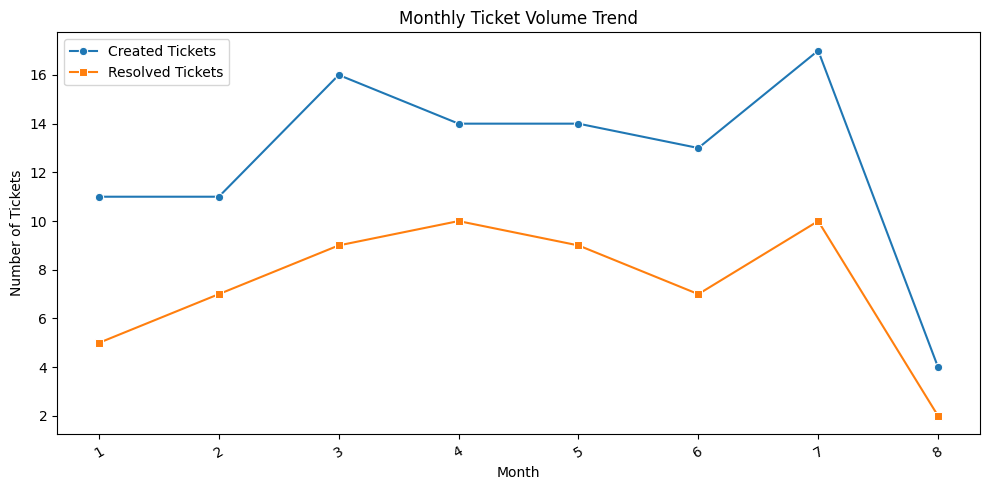

In [209]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=Monthly_trends,
    x="created_month_str",
    y="created_tickets",
    marker="o",
    label="Created Tickets"
)
sns.lineplot(
    data=Monthly_trends,
    x="created_month_str",
    y="resolved_tickets",
    marker="s",
    label="Resolved Tickets"
)
plt.title("Monthly Ticket Volume Trend")
plt.xlabel("Month")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

In [216]:
# Export the outputs
output_path = Path("output")

output_path.mkdir(
    parents=True,
    exist_ok=True
)
team_workload.to_csv(output_path /"team_workload.csv",index=False)
status_summary.to_csv(output_path / "tickets status summary.csv",index=False)
team_resolution.to_csv(output_path / "team Rsolutatom sammary",index=False)
Monthly_trends.to_csv(output_path / "Maonthly tickets Trends",index=False)

